In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pints
import pints.io
import pints.plot
import scipy.interpolate
import random
from collections import defaultdict
import matplotlib

import mechanistic_model
import likelihood

In [2]:
df = pd.read_csv('data/df_covariates_better_date.csv')

df["weight2"] = df["weight"] ** 2

In [3]:
X_a = df[[]]
X_a.insert(0, 'Ones', 1) 

X_h = df[["f.acc_condH",
          "f.acc_condM",  # 4
          "f.acc_condT",   # 5
          
          "f.exp_condH",
          "f.exp_condM",
          "f.exp_condT",
          
          "f.week6",
          
          "f.acc_condH:f.week6",
          "f.acc_condM:f.week6",  # 11
          "f.acc_condT:f.week6",   # 12
          
          "weight",
          "weight2"]]

X_h.insert(0, 'Ones', 1)

ns_prey_eaten = df["n_prey_eaten"]
ns_prey_initial = df["n_prey_initial"]


ids = df["fish.id"]

# likelihood for a particular parameter set
beta = np.zeros(X_a.shape[1])
gamma = np.zeros(X_h.shape[1])

In [4]:
dists[25]

NameError: name 'dists' is not defined

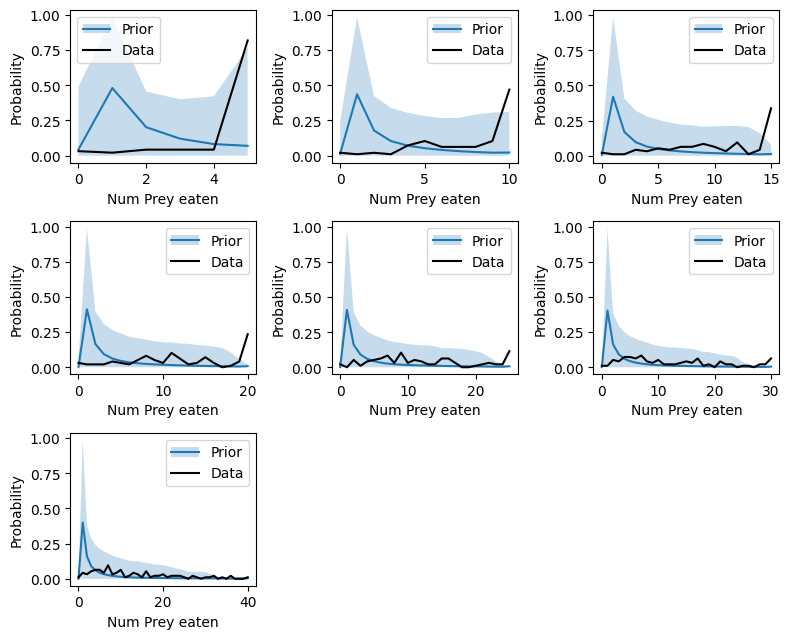

In [7]:
# Prior Predictive

dists = defaultdict(list)
data_dists = defaultdict(list)

as_observed = []
hs_observed = []
ns_prey_eaten_observed = []

prior = pints.MultivariateGaussianLogPrior([0] * p.n_parameters(), 1.0 * np.identity(p.n_parameters()))

prior_samples = prior.sample(100)

for x in prior_samples:

    for n_prey_eaten, n_prey_initial, x_a, x_h in zip(
    ns_prey_eaten, ns_prey_initial, X_a.to_numpy(), X_h.to_numpy()
    ):
        
        beta = x[:len(beta)]
        gamma = x[len(beta):]
        a = likelihood.a_parameter_creator(beta, x_a)
        r = likelihood.a_parameter_creator(gamma, x_h)
        
        p_eaten = mechanistic_model.solve_system_simple_h_simplex(n_prey_initial, a, r)
        as_observed.append(a)
        hs_observed.append(r)
        ns_prey_eaten_observed.append(n_prey_initial)
        dists[n_prey_initial].append(np.asarray(p_eaten))
        data = [0] * (n_prey_initial + 1)
        data[n_prey_eaten] = 1
        data_dists[n_prey_initial].append(np.asarray(data))

ns = sorted(list(set(ns_prey_initial)))

fig = plt.figure(figsize=(8, 6.5))

for i, n in enumerate(ns):
    ax = fig.add_subplot(3, 3, i+1)
    
    m = dists[n]
    d = data_dists[n]

    x = np.arange(n+1)
    l1, = ax.plot(x, np.mean(m, axis=0), label='Inferred')
    p1 = ax.fill_between(x, np.percentile(m, 2.5, axis=0), np.percentile(m, 97.5, axis=0), alpha=0.25)

    l2, = ax.plot(x, np.mean(d, axis=0), color='k', label='Data')

    ax.legend(((l1, p1), l2), ['Prior', 'Data'])

    ax.set_xlabel('Num Prey eaten')
    ax.set_ylabel('Probability')


fig.set_tight_layout(True)
plt.show()


In [5]:
class Likelihood(pints.LogPDF):
    def __init__(self, ns_prey_eaten, ns_prey_initial, X_a, X_h, n_beta, n_gamma):
        super().__init__()
        self.ns_prey_eaten = ns_prey_eaten
        self.ns_prey_initial = ns_prey_initial

        self.X_a = X_a
        self.X_h = X_h

        self.n_beta = n_beta
        self.n_gamma = n_gamma

    def __call__(self, x):
        beta = x[:self.n_beta]
        gamma = x[self.n_beta:]

        return mechanistic_model.log_likelihood_all_fish(ns_prey_eaten, ns_prey_initial, beta, gamma, X_a, X_h)
    
    def n_parameters(self):
        return self.n_beta + self.n_gamma


p = Likelihood(ns_prey_eaten, ns_prey_initial, X_a, X_h, len(beta), len(gamma))

prior = pints.MultivariateGaussianLogPrior([0] * p.n_parameters(), 1.0 * np.identity(p.n_parameters()))

posterior = pints.LogPosterior(p, prior)

best_opt_result = -np.inf
best_opt_x = -1
for i in range(10):
    opt = pints.OptimisationController(
        posterior,
        prior.sample(),
        method=pints.CMAES,
    )
    opt.set_max_iterations(400)
    x, err = opt.run()
    if err > best_opt_result:
        best_opt_x = np.copy(x)
        best_opt_result = err
    

mcmc = pints.MCMCController(
    posterior,
    3,
    [best_opt_x, best_opt_x, best_opt_x],
    method=pints.HaarioBardenetACMC,
)

mcmc.set_max_iterations(50000)

mcmc.set_chain_filename('run0_noyear_opt_weight2.csv')

chains0 = mcmc.run()


Maximising LogPDF
Using Covariance Matrix Adaptation Evolution Strategy (CMA-ES)
Running in sequential mode.
Population size: 11
Iter. Eval.  Best      Current   Time m:s
0     11     -9665.328 -9665.328   0:00.8
1     22     -9544.226 -9544.226   0:01.6

----------------------------------------
Unexpected termination.
Current score: -9544.22565313104
Current position:
 1.84076684892495818e-01
 4.19079318686839786e-01
-1.78272579734969416e+00
-5.81471026052630235e-01
 2.65751570689096805e+00
-1.75550502048578050e+00
-5.96402174712636901e-01
 4.79176896110343475e-01
-5.71345470064218208e-01
 5.34499536044565238e-01
 1.29120681932910020e+00
 4.17114923074538346e-01
-4.92081958282007292e-01
 5.49336705124567781e-01
----------------------------------------


KeyboardInterrupt: 

In [9]:
params = [ "intercept_a",
         "intercept_h",
          "f.acc_condH_h",
          "f.acc_condM_h",
          "f.acc_condT_h", 
          "f.exp_condH_h",
          "f.exp_condM_h",
          "f.exp_condT_h",
          "f.week6_h",
          "f.acc_condH:f.week6_h",
          "f.acc_condM:f.week6_h",
          "f.acc_condT:f.week6_h",
          "weight_h",
          "weight_h^2",
]


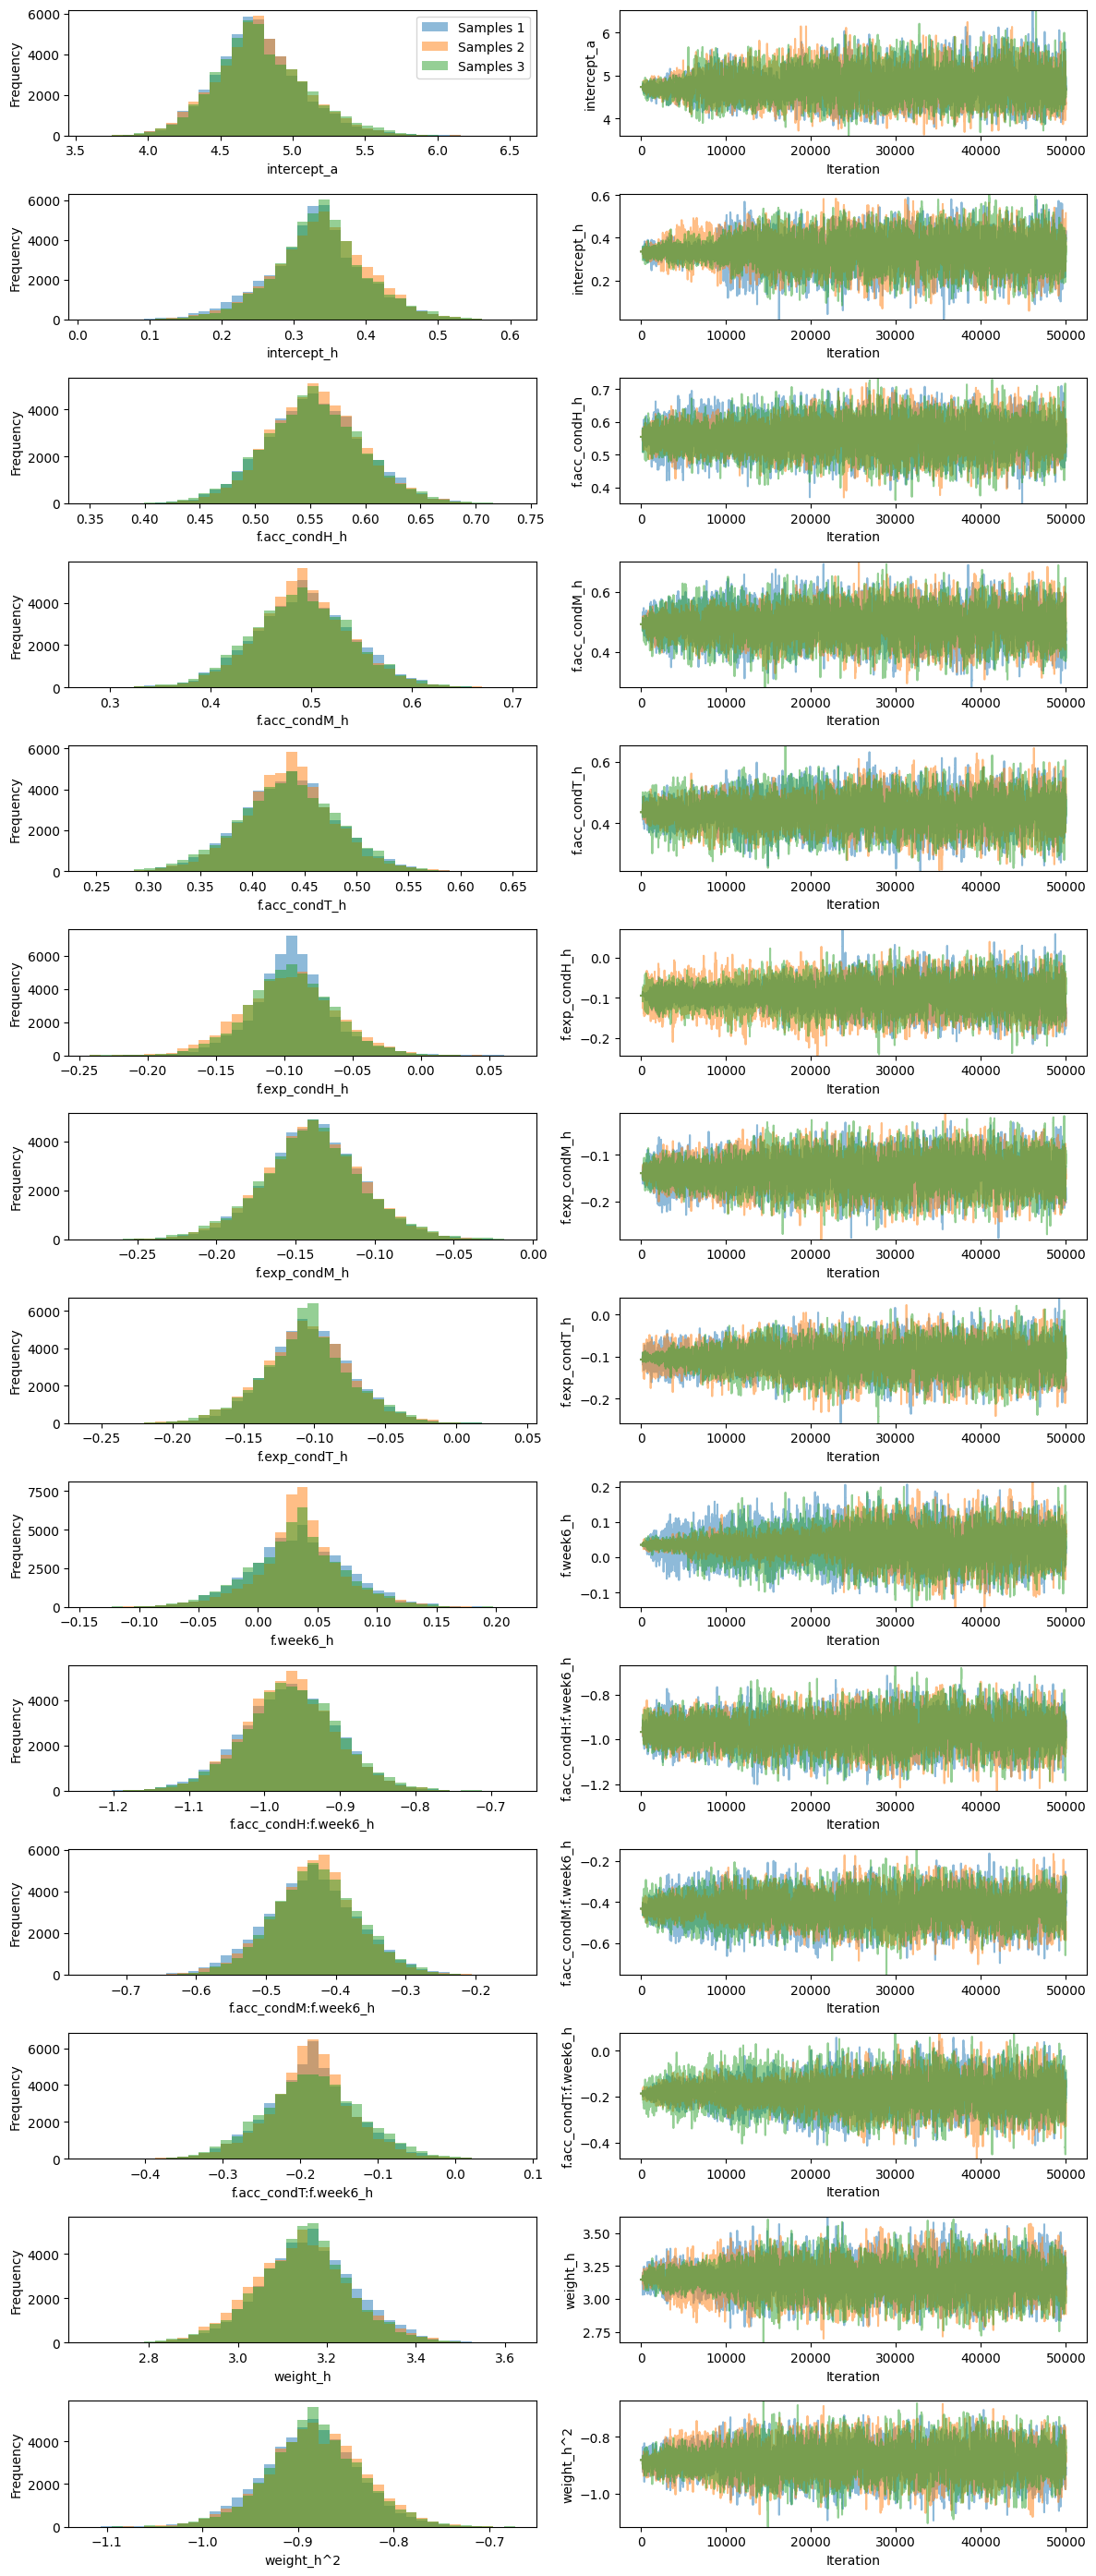

In [10]:
pints.plot.trace(chains0[:, :, :], parameter_names=params)
plt.show()

In [24]:
for chain in range(3):
    df = pd.DataFrame({param: chains0[chain, :, i] for i, param in enumerate(params)})
    df.to_csv('chains_all_h_chain{}.csv'.format(chain), index=False)

In [20]:
df = []


for fish_id, n_prey_eaten, n_prey_initial, x_a, x_h in zip(
ids, ns_prey_eaten, ns_prey_initial, X_a.to_numpy(), X_h.to_numpy()
):
    for i, x in enumerate(chains0[0, 25000::500, :]):

        beta = x[:p.n_beta]
        gamma = x[p.n_beta:]
        a = fastprey.likelihood.a_parameter_creator(beta, x_a)
        r = fastprey.likelihood.a_parameter_creator(gamma, x_h)
        
        p_eaten = fastprey.mechanistic_model.solve_system_simple_h_simplex(n_prey_initial, a, r)

        p_eaten = list(p_eaten)

        if len(p_eaten) < 41:
            p_eaten = p_eaten + [0] * (41-len(p_eaten))

        p_eaten = np.asarray(p_eaten)

        df.append([fish_id, n_prey_initial, n_prey_eaten, i,] + list(p_eaten))

df = np.asarray(df)

df = pd.DataFrame(df, columns=['fish_id', 'n_prey_initial', 'n_prey_eaten', 'mcmc_iteration',] + ['posterior_p_{}'.format(i) for i in range(41)])
        

In [21]:
df.to_csv('posterior_samples_all_h_weight2.csv')

In [ ]:
all_lls = []

for x in chains0[0, 25000::500, :]:
    lls = []

    for n_prey_eaten, n_prey_initial, x_a, x_h in zip(
    ns_prey_eaten, ns_prey_initial, X_a.to_numpy(), X_h.to_numpy()
    ):   
        beta = x[:p.n_beta]
        gamma = x[p.n_beta:]
        ll = mechanistic_model.log_likelihood_single_fish(n_prey_eaten, n_prey_initial, beta, gamma, x_a, x_h)
        lls.append(ll)
    
    all_lls.append(lls)

all_lls = np.asarray(all_lls)

In [23]:
np.savetxt('samples_ll_all_h_weight2.csv', all_lls)

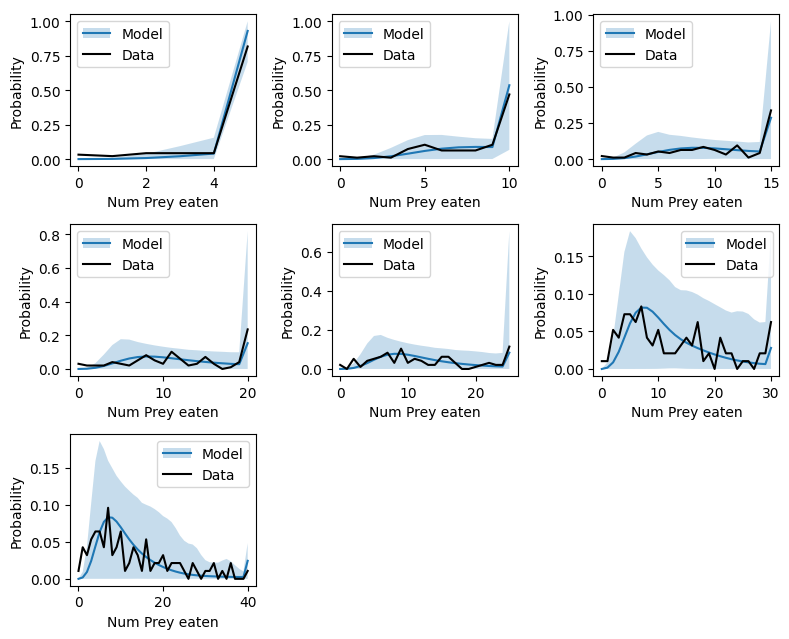

In [34]:
dists = defaultdict(list)
data_dists = defaultdict(list)

as_observed = []
hs_observed = []
ns_prey_eaten_observed = []

for x in chains0[0, 5000::10, :]:

    for n_prey_eaten, n_prey_initial, x_a, x_h in zip(
    ns_prey_eaten, ns_prey_initial, X_a.to_numpy(), X_h.to_numpy()
    ):
        
        beta = x[:p.n_beta]
        gamma = x[p.n_beta:]
        a = fastprey.likelihood.a_parameter_creator(beta, x_a)
        r = fastprey.likelihood.a_parameter_creator(gamma, x_h)
        
        p_eaten = fastprey.mechanistic_model.solve_system_simple_h_simplex(n_prey_initial, a, r)
        as_observed.append(a)
        hs_observed.append(r)
        ns_prey_eaten_observed.append(n_prey_initial)
        dists[n_prey_initial].append(np.asarray(p_eaten))
        data = [0] * (n_prey_initial + 1)
        data[n_prey_eaten] = 1
        data_dists[n_prey_initial].append(np.asarray(data))

ns = sorted(list(set(ns_prey_initial)))

fig = plt.figure(figsize=(8, 6.5))

for i, n in enumerate(ns):
    ax = fig.add_subplot(3, 3, i+1)
    
    m = dists[n]
    d = data_dists[n]

    x = np.arange(n+1)
    l1, = ax.plot(x, np.mean(m, axis=0), label='Inferred')
    p1 = ax.fill_between(x, np.percentile(m, 5, axis=0), np.percentile(m, 95, axis=0), alpha=0.25)

    l2, = ax.plot(x, np.mean(d, axis=0), color='k', label='Data')

    ax.legend(((l1, p1), l2), ['Model', 'Data'])

    ax.set_xlabel('Num Prey eaten')
    ax.set_ylabel('Probability')



fig.set_tight_layout(True)
plt.show()




In [35]:
for i, n in enumerate(ns):
    
    m = dists[n]
    d = data_dists[n]

    x = np.arange(n+1)
    mean = np.mean(m, axis=0)
    lower = np.percentile(m, 5, axis=0)
    upper = np.percentile(m, 95, axis=0)
    data = np.mean(d, axis=0)

    df = pd.DataFrame({'num prey': x, 'mean': mean, 'lower': lower, 'upper': upper, 'data': data})

    df.to_csv('run1_posterior.csv'.format(n))

In [41]:
all_lls = []

for x in chains0[0, 5000::25, :]:
    lls = []

    for n_prey_eaten, n_prey_initial, x_a, x_h in zip(
    ns_prey_eaten, ns_prey_initial, X_a.to_numpy(), X_h.to_numpy()
    ):   
        beta = x[:p.n_beta]
        gamma = x[p.n_beta:]
        ll = fastprey.mechanistic_model.log_likelihood_single_fish(n_prey_eaten, n_prey_initial, beta, gamma, x_a, x_h)
        lls.append(ll)
    
    all_lls.append(lls)

all_lls = np.asarray(all_lls)

In [42]:
all_lls.shape

(200, 668)

In [43]:
np.savetxt('run1_ll.csv', all_lls)

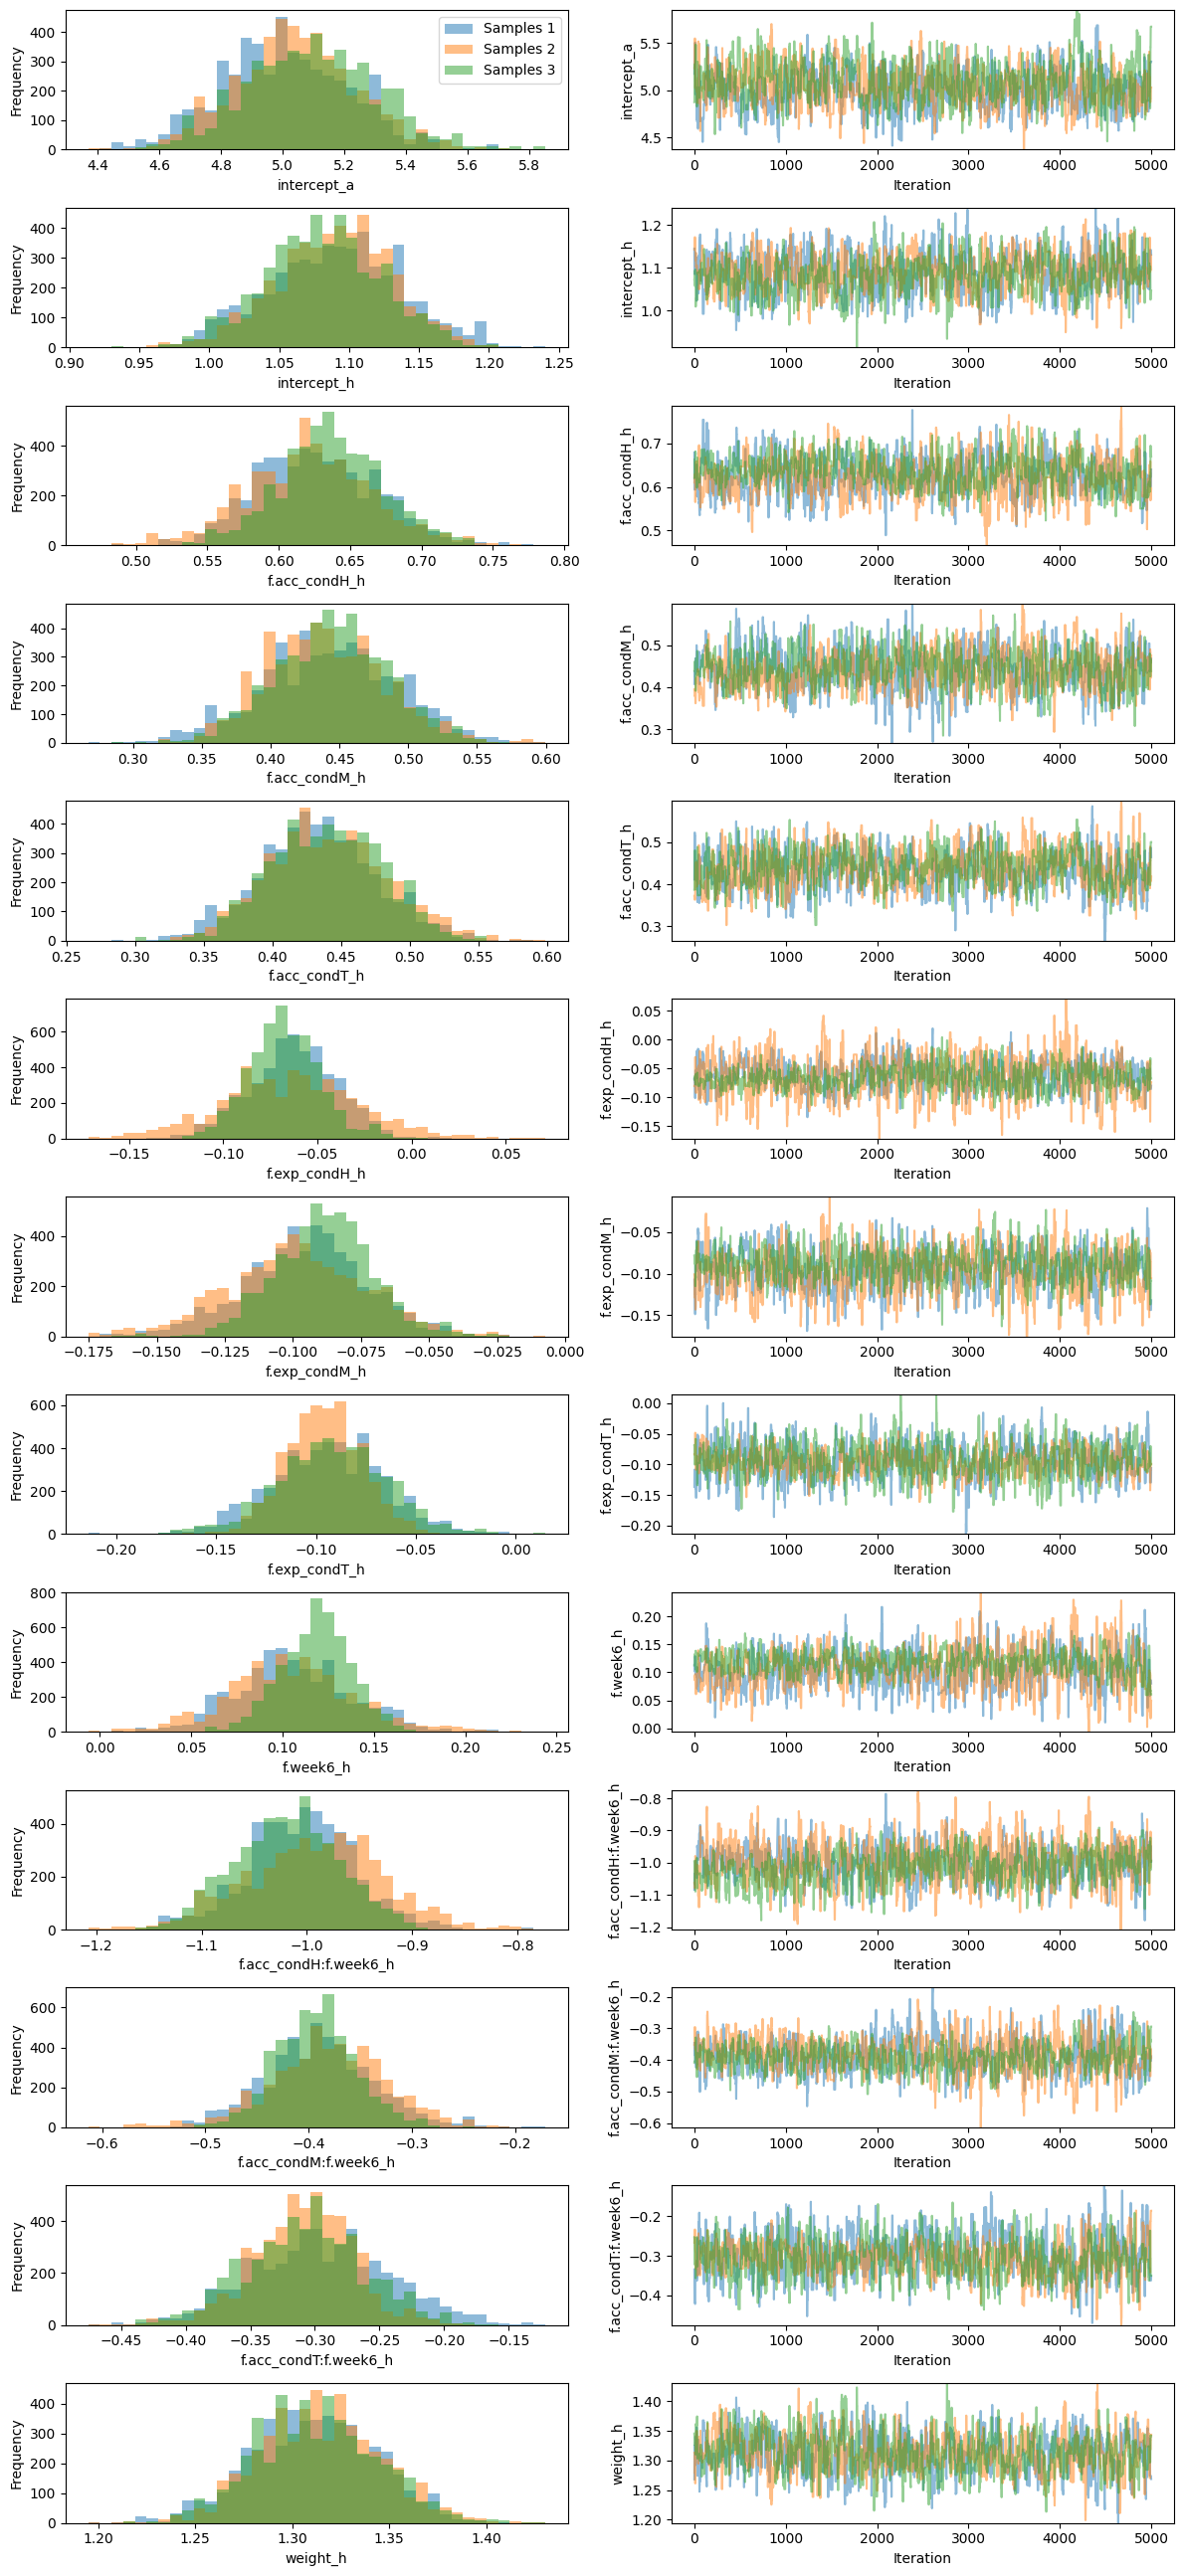

In [25]:
params = [ "intercept_a",
         "intercept_h",
          "f.acc_condH_h",
          "f.acc_condM_h",
          "f.acc_condT_h", 
          "f.exp_condH_h",
          "f.exp_condM_h",
          "f.exp_condT_h",
          "f.week6_h",
          "f.acc_condH:f.week6_h",
          "f.acc_condM:f.week6_h",
          "f.acc_condT:f.week6_h",
          "weight_h",
]


pints.plot.trace(chains0[:, 5000:, :], parameter_names=params)
plt.show()

In [10]:
chains0 = pints.io.load_samples('run0_noyear.csv', n=3)

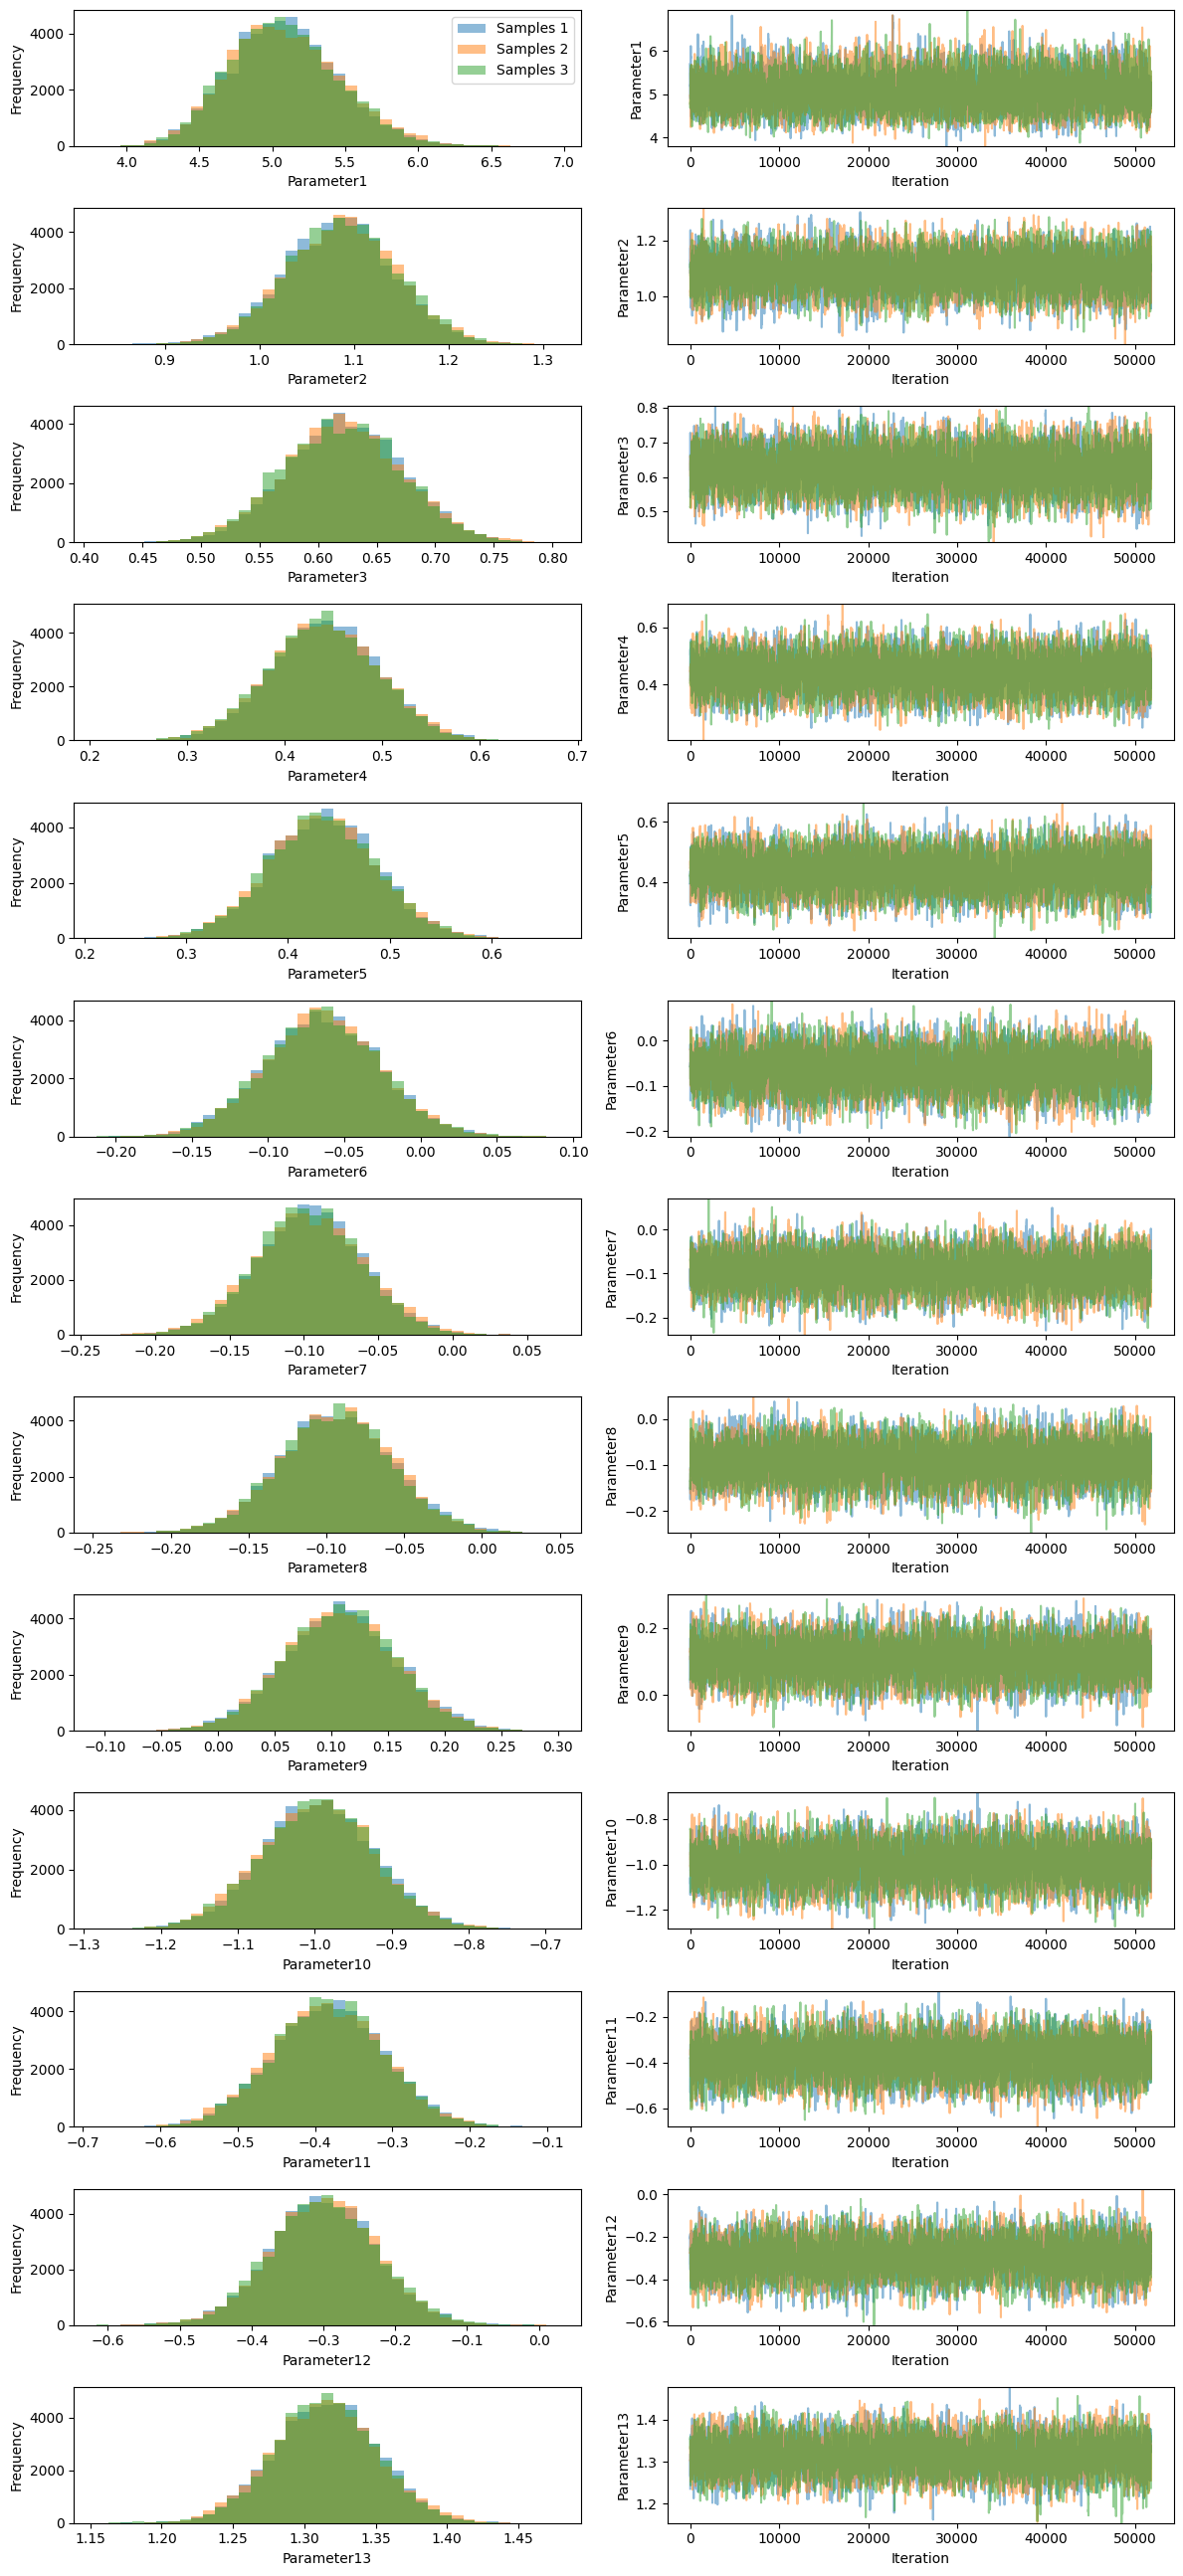

In [13]:
chains0 = np.asarray(chains0)
pints.plot.trace(chains0[:, 50000:, :])
plt.show()